In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "02"

# 02 · Does it deliver what is asked?

**Question:** when we ask for a harmonic current, does that current come out, on the real HIL404 and
in Virtual HIL?

**Setup.** `run_bench.py` steps the grid stiff → SCR 20 → SCR 10 → SCR 5 with every order at its
limit, waits, and records 10 cycles (50 kHz sampling). Each order is found by a least-squares fit.
`test_scenarios.py` then drives the SCADA panel through scenarios A-G. Both were run in Virtual HIL
(4 Oct 2026) and on the HIL404 (5 Oct 2026).

At SCR 5 with 750 V DC the bench capture was taken while the inverter was still recovering from the
grid step (notebook 06), so for SCR 5 we use scenario F (1000 V DC), which is settled.

## What the current looks like

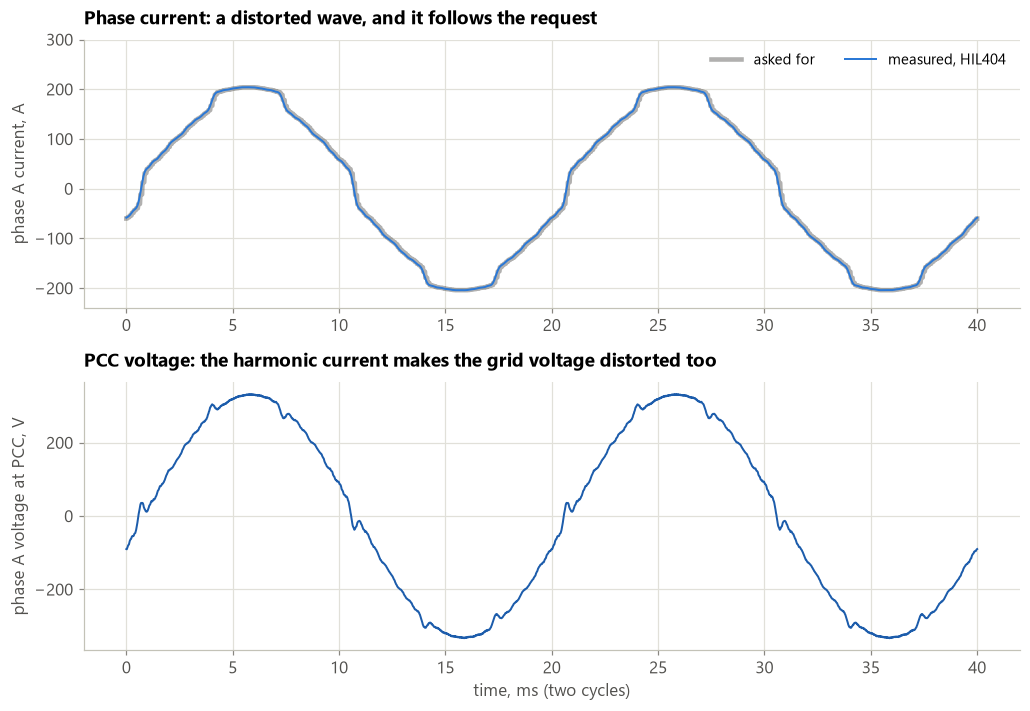

In [2]:
w = A.load("bench_hil404_wave_SCR20.csv")
m = w.t < 0.04
fig, ax = A.panels(2, h=3.3)
ax[0].plot(w.t[m] * 1e3, w.iref_a[m], color=A.LIMIT, lw=3, alpha=0.45, label="asked for")
ax[0].plot(w.t[m] * 1e3, w.Ia[m], color=A.USED, lw=1.3, label="measured, HIL404")
ax[0].set_ylabel("phase A current, A"); ax[0].set_ylim(-240, 300); ax[0].legend(loc="upper right", ncol=2)
ax[0].set_title("Phase current: a distorted wave, and it follows the request")
ax[1].plot(w.t[m] * 1e3, w.Va[m], color=A.GRID_COLOR["SCR 10"], lw=1.3)
ax[1].set_ylabel("phase A voltage at PCC, V"); ax[1].set_xlabel("time, ms (two cycles)")
ax[1].set_title("PCC voltage: the harmonic current makes the grid voltage distorted too")
A.save(fig, "02_waveforms")

**Reading.** The current is deliberately distorted (all 16 orders at their limits, THD about 6.8 %). The
measured line sits on top of the requested one. The PCC voltage is distorted too, because the harmonic
currents flow through the grid impedance.

## Every order, every grid, both platforms

| grid | HIL404 worst % | Virtual HIL worst % |
|---|---|---|
| SCR 10 | 0.204 | 0.264 |
| SCR 20 | 0.134 | 0.112 |
| SCR 5 | 0.261 | 0.306 |
| stiff | 0.457 | 0.423 |

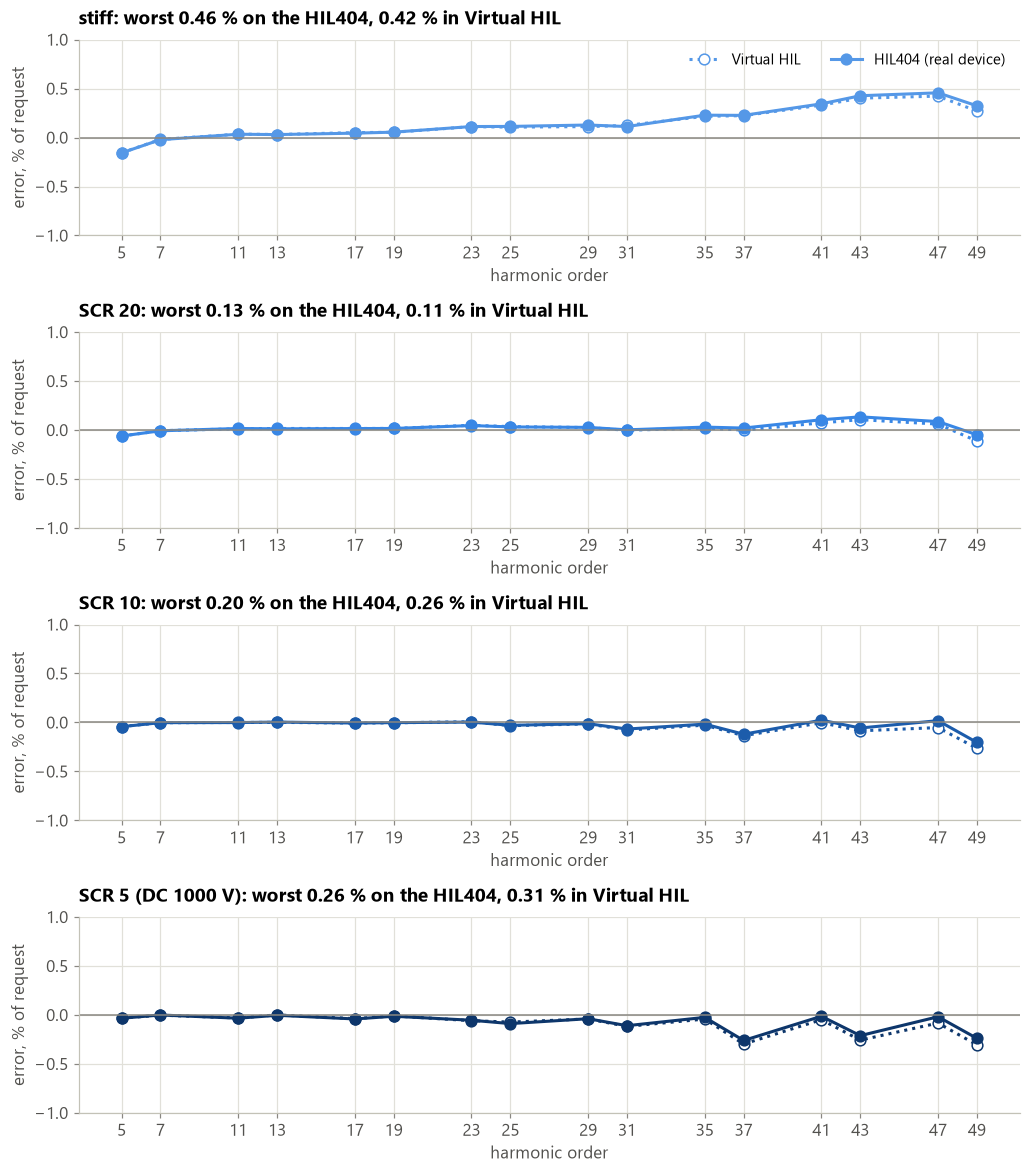

In [3]:
def settled(dev):
    b = A.load("bench_%s.csv" % dev)
    s = A.load("scenarios_%s.csv" % dev if dev == "hil404" else "scenarios.csv")
    f = s[s.scenario == "F"].drop(columns="scenario").assign(grid="SCR 5")
    return pd.concat([b[b.grid != "SCR 5"], f]).query("order > 1").assign(device=dev)
d = pd.concat([settled("vhil"), settled("hil404")])
fig, ax = A.panels(4, h=2.7)
for a, g in zip(ax, A.GRIDS):
    for dev in ("vhil", "hil404"):
        x = d[(d.grid == g) & (d.device == dev)]
        a.plot(x.order, x.I_error_pct_of_request, ls="-" if dev == "hil404" else ":", color=A.GRID_COLOR[g] if g != "stiff" else "#5598e7", **A.DEVICE[dev])
    a.axhline(0, color=A.MUTED, lw=1); a.set_ylim(-1, 1); A.orders_axis(a)
    a.set_ylabel("error, % of request")
    wh = d[(d.grid == g) & (d.device == "hil404")].I_error_pct_of_request.abs().max()
    wv = d[(d.grid == g) & (d.device == "vhil")].I_error_pct_of_request.abs().max()
    a.set_title("%s%s: worst %.2f %% on the HIL404, %.2f %% in Virtual HIL" % (g, " (DC 1000 V)" if g == "SCR 5" else "", wh, wv))
ax[0].legend(loc="upper right", ncol=2)
A.save(fig, "02_error_per_order", d)
w = d.groupby(["grid", "device"]).I_error_pct_of_request.apply(lambda s: s.abs().max()).unstack()
display(Markdown(A.md_table(w.reset_index().rename(columns={"vhil": "Virtual HIL worst %", "hil404": "HIL404 worst %"}))))
claim("C2.1", "HIL404, full request, worst order error on stiff / SCR 20 / SCR 10 / SCR 5 (1000 V)",
      " / ".join("%.2f %%" % w.loc[g, "hil404"] for g in A.GRIDS), "results/bench_hil404.csv, scenarios_hil404.csv (F)")

**Reading.** Each panel is one grid. Filled dots: the real HIL404. Hollow dots: Virtual HIL. All points
stay inside ±1 % of the request, and the two platforms agree with each other.

## Scenarios A-G through the SCADA panel

These change one thing at a time through the panel's own buttons and sliders: grid frequency, background
distortion, a weak grid with more DC voltage, and individual sliders.

(The first Virtual HIL run of B-D used a plain Fourier transform, which leaks between neighbouring
orders when the frequency is not exactly 50 Hz. They were re-run with the least-squares fit used
everywhere else; the re-run is shown.)

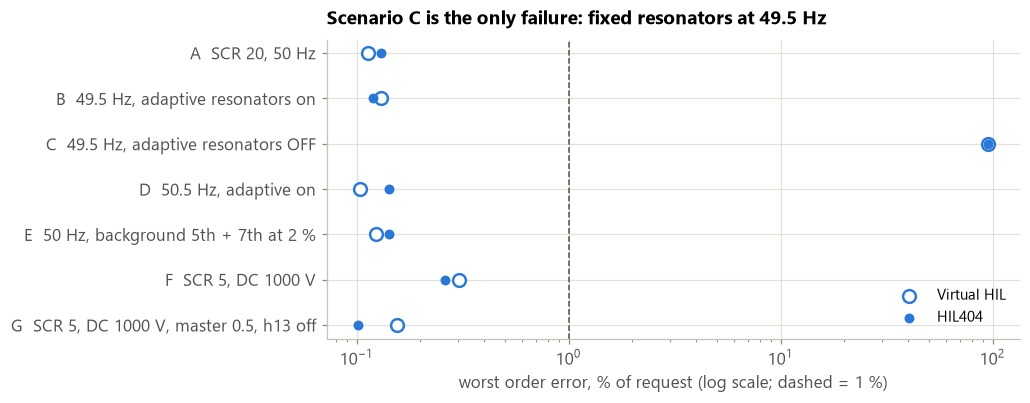

In [4]:
v = pd.concat([A.load("scenarios_summary_freq.csv"), A.load("scenarios_summary.csv").query("scenario in ['E','F','G']")])
h = A.load("scenarios_summary_hil404.csv")
s = v[["scenario", "what", "worst_order_error_pct"]].merge(h[["scenario", "worst_order_error_pct", "THD_V_pct", "meter_THDv"]], on="scenario", suffixes=("_vhil", "_hil404"))
fig, ax = A.panels(1, h=3.8)
y = np.arange(len(s))[::-1]
ax[0].scatter(s.worst_order_error_pct_vhil, y, s=70, facecolor="white", edgecolor=A.USED, lw=1.6, label="Virtual HIL", zorder=3)
ax[0].scatter(s.worst_order_error_pct_hil404, y, s=30, color=A.USED, label="HIL404", zorder=4)
ax[0].set_yticks(y); ax[0].set_yticklabels(s.scenario + "  " + s.what)
ax[0].set_xscale("log"); ax[0].axvline(1, color=A.LIMIT, ls="--", lw=1)
ax[0].set_xlabel("worst order error, % of request (log scale; dashed = 1 %)")
ax[0].set_title("Scenario C is the only failure: fixed resonators at 49.5 Hz")
ax[0].legend(loc="lower right")
A.save(fig, "02_scenarios", s)
claim("C2.2", "Scenarios A-G: worst error on the HIL404 except C (fixed resonators off-nominal)",
      "%.2f %% (C: %.0f %%)" % (s[s.scenario != "C"].worst_order_error_pct_hil404.max(), s[s.scenario == "C"].worst_order_error_pct_hil404.iloc[0]),
      "results/scenarios_summary_hil404.csv")

**Reading.** Everything is below 0.3 % except C, where the resonators are not retuned to the grid
frequency (notebook 05 explains why).

## Can you trust the live meter on the panel?

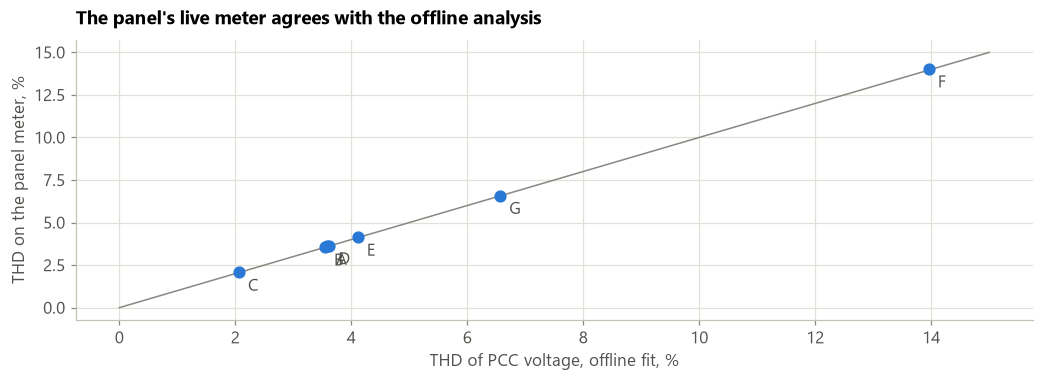

In [5]:
fig, ax = A.panels(1, h=3.6)
ax[0].plot([0, 15], [0, 15], color=A.MUTED, lw=1)
ax[0].scatter(h.THD_V_pct, h.meter_THDv, color=A.USED, zorder=3)
for _, r in h.iterrows():
    ax[0].annotate(r.scenario, (r.THD_V_pct, r.meter_THDv), xytext=(6, -12), textcoords="offset points", color=A.INK2)
ax[0].set_xlabel("THD of PCC voltage, offline fit, %"); ax[0].set_ylabel("THD on the panel meter, %")
ax[0].set_title("The panel's live meter agrees with the offline analysis")
A.save(fig, "02_meter", h[["scenario", "THD_V_pct", "meter_THDv"]])
claim("C2.3", "Largest difference between panel meter and offline THD_V (HIL404, A-G)",
      "%.2f percentage points" % (h.meter_THDv - h.THD_V_pct).abs().max(), "results/scenarios_summary_hil404.csv")

## Real device vs Virtual HIL over the whole sweep (82 operating points)

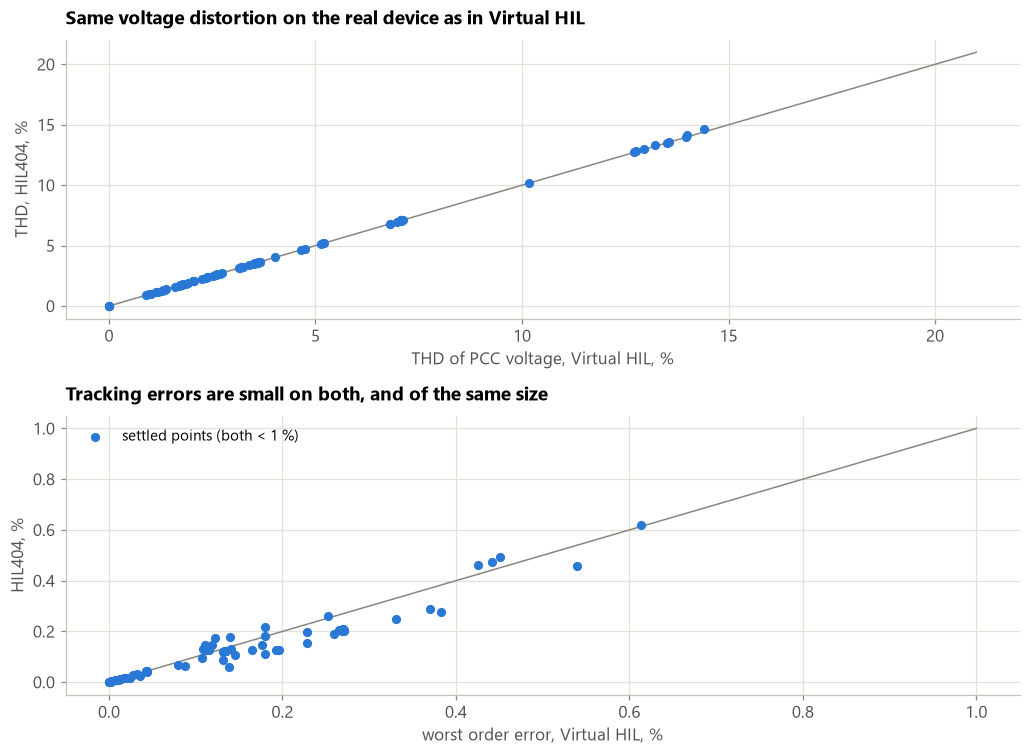

In [6]:
pv, ph = A.load("sweep_vhil_points.csv"), A.load("sweep_hil404_points.csv")
j = pv.merge(ph, on="point", suffixes=("_v", "_h"))
fig, ax = A.panels(2, h=3.5)
ax[0].plot([0, 21], [0, 21], color=A.MUTED, lw=1)
ax[0].scatter(j.THD_V_pct_v, j.THD_V_pct_h, color=A.USED, s=25, zorder=3)
ax[0].set_xlabel("THD of PCC voltage, Virtual HIL, %"); ax[0].set_ylabel("THD, HIL404, %")
ax[0].set_title("Same voltage distortion on the real device as in Virtual HIL")
ok = (j.worst_order_error_pct_v < 1) & (j.worst_order_error_pct_h < 1)
ax[1].scatter(j.worst_order_error_pct_v[ok], j.worst_order_error_pct_h[ok], color=A.USED, s=25, zorder=3, label="settled points (both < 1 %)")
ax[1].plot([0, 1], [0, 1], color=A.MUTED, lw=1)
ax[1].set_xlabel("worst order error, Virtual HIL, %"); ax[1].set_ylabel("HIL404, %")
ax[1].set_title("Tracking errors are small on both, and of the same size")
ax[1].legend(loc="upper left")
A.save(fig, "02_vhil_vs_hil404", j[["point", "sweep_v", "grid_v", "THD_V_pct_v", "THD_V_pct_h", "worst_order_error_pct_v", "worst_order_error_pct_h"]])
claim("C2.4", "Over 82 sweep points, largest THD_V difference HIL404 vs Virtual HIL",
      "%.2f percentage points" % (j.THD_V_pct_v - j.THD_V_pct_h).abs().max(), "results/sweep_vhil_points.csv, sweep_hil404_points.csv")
claim("C2.5", "Points with worst error below 1 % on both platforms", "%d of %d" % (ok.sum(), len(j)),
      "same files; the rest are SCR 5 / low-DC points still recovering after a step (notebook 06) or fixed resonators off 50 Hz (05)")

**Reading.** Top: each dot is one operating point; on the diagonal means the HIL404 and Virtual HIL
gave the same distortion. Bottom: tracking errors for the points that had settled. **So a user without
the hardware can trust Virtual HIL for this model.** The HIL404 ran in real time (simulated time =
wall-clock time), so the 10 kHz controller fits its 100 µs slot.

## Limits of this notebook
- Accuracy is measured at the 16 regulated orders only (other frequencies: notebook 03).
- Each number is one 10-cycle capture after a settle time, not a long average.

In [7]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C2.1 | HIL404, full request, worst order error on stiff / SCR 20 / SCR 10 / SCR 5 (1000 V) | 0.46 % / 0.13 % / 0.20 % / 0.26 % | results/bench_hil404.csv, scenarios_hil404.csv (F) |
| C2.2 | Scenarios A-G: worst error on the HIL404 except C (fixed resonators off-nominal) | 0.26 % (C: 95 %) | results/scenarios_summary_hil404.csv |
| C2.3 | Largest difference between panel meter and offline THD_V (HIL404, A-G) | 0.06 percentage points | results/scenarios_summary_hil404.csv |
| C2.4 | Over 82 sweep points, largest THD_V difference HIL404 vs Virtual HIL | 0.24 percentage points | results/sweep_vhil_points.csv, sweep_hil404_points.csv |
| C2.5 | Points with worst error below 1 % on both platforms | 63 of 82 | same files; the rest are SCR 5 / low-DC points still recovering after a step (notebook 06) or fixed resonators off 50 Hz (05) |